# TEST histórico — todas as métricas do pipeline final
Este notebook apresenta a avaliação do **Random Forest com StandardScaler, SMOTE
e seleção conjunta de features**, usando o threshold **0,70** congelado no TRAIN.

A avaliação foi solicitada depois das iterações de modelagem. Este é o mesmo período
histórico já avaliado na primeira rodada: **reavaliação retrospectiva, não um TEST
independente novo**. Nenhum parâmetro, feature, scaler ou threshold foi reajustado aqui.

Os cálculos ficam em `src/fraud_detection/final_test.py`; este notebook **apenas lê
artefatos**, sem treinar nem prever novamente. Para gerar os resultados pela primeira
vez: `python -m fraud_detection.final_test`. Uma execução já existente é protegida
contra sobrescrita; `--output` permite reprodução separada, sem tornar o TEST novo.

[Guia completo de métricas](../docs/metrics_guide.md) ·
[Relatório resumido](../reports/final_test_results.md)

**Rodada posterior F3:** o artefato recall_f3_pipeline.joblib usa outro threshold.
Ele não foi reavaliado neste TEST. As métricas deste notebook continuam
descrevendo exclusivamente o threshold F2 **0,70**.

In [1]:
# Localiza a raiz e carrega somente resultados agregados; nenhuma transação é exposta.
from pathlib import Path
import json
import pandas as pd
from IPython.display import display, Image, Markdown
from fraud_detection.reporting import readable_table

ROOT = Path.cwd()
if not (ROOT / "pyproject.toml").exists():
    ROOT = ROOT.parent
if not (ROOT / "pyproject.toml").exists():
    raise RuntimeError("Abra o notebook pela raiz ou pela pasta notebooks.")
METRICS, FIGURES = ROOT / "reports/metrics", ROOT / "reports/figures"
EXPERIMENTS = ROOT / "reports/experiments"

def read_json(path):
    if not path.exists():
        raise FileNotFoundError(f"Artefato ausente: {path.name}. Execute python -m fraud_detection.final_test.")
    return json.loads(path.read_text(encoding="utf-8"))

def table(name):
    path = METRICS / name
    if not path.exists():
        raise FileNotFoundError(f"Artefato ausente: {name}. Execute python -m fraud_detection.final_test.")
    return pd.read_csv(path)

def figure(name):
    display(Image(filename=str(FIGURES / name), width=1100))

result = read_json(METRICS / "final_test_metrics.json")
manifest = read_json(EXPERIMENTS / "final_test_manifest.json")
assert manifest["training_performed"] is False
assert manifest["threshold_tuning_performed"] is False

## 1. O que foi avaliado e como a base foi separada
Uma linha é uma transação; **Class=1 significa fraude** e Class=0, legítima.
O TEST é a janela dos últimos 20% da **duração temporal**, não 20% das linhas.
Cópias exatas foram retiradas deterministicamente, preservando o CSV original.

A ordem do pipeline é imputação → StandardScaler → SMOTE (somente no fit de treino)
→ Random Forest. Na inferência do TEST, o pipeline aplica os componentes ajustados
e **não reamostra**. As 14 features foram escolhidas no TRAIN pela regra conjunta
`abs(Pearson) < 0,090 AND importância por permutação < 0,100` para remover.

Os hashes abaixo identificam exatamente o dataset, o artefato e o manifesto de
seleção avaliados. Essa rastreabilidade não transforma a avaliação retrospectiva
em validação prospectiva.

In [2]:
display({
    "Modelo": result["model"],
    "Threshold congelado": result["threshold"],
    "Features mantidas": result["selected_features"],
    "Data da avaliação (America/Fortaleza)": manifest["evaluated_at"],
    "TRAIN: transações": manifest["train_rows"],
    "TEST: transações": result["rows"],
    "TEST: início de Time": manifest["test_time_min"],
    "TEST: fim de Time": manifest["test_time_max"],
    "Hash do dataset": manifest["dataset_sha256"],
    "Hash do pipeline": manifest["artifact_sha256"],
    "Hash da seleção anterior ao teste": manifest["selection_sha256"],
    "Teste independente novo?": result["independent_test"],
})
composition = pd.DataFrame([
    {"Classe real": "Legítima (0)", "Transações": result["negatives"],
     "Percentual do TEST": 100*result["negatives"]/result["rows"]},
    {"Classe real": "Fraude (1)", "Transações": result["positives"],
     "Percentual do TEST": 100*result["positives"]/result["rows"]},
])
display(composition.style.format({"Percentual do TEST": "{:.4f}%"}))
display(Markdown(
    f"O TEST tem **{result['rows']:,} transações**, sendo **{result['positives']} fraudes** "
    f"(**{result['prevalence']:.4%}**). A prevalência descreve a base; não mede a habilidade do modelo."
))

{'Modelo': 'random_forest__scaled_smote_selected',
 'Threshold congelado': 0.7,
 'Features mantidas': ['V1',
  'V2',
  'V3',
  'V4',
  'V5',
  'V7',
  'V9',
  'V10',
  'V11',
  'V12',
  'V14',
  'V16',
  'V17',
  'V18'],
 'Data da avaliação (America/Fortaleza)': '2026-10-27T22:37:12.645143-03:00',
 'TRAIN: transações': 210292,
 'TEST: transações': 73434,
 'TEST: início de Time': 138234.0,
 'TEST: fim de Time': 172792.0,
 'Hash do dataset': '76274b691b16a6c49d3f159c883398e03ccd6d1ee12d9d8ee38f4b4b98551a89',
 'Hash do pipeline': '82b0b49ec4ca27dcab1b6d18fa1d419e8ccbc399aa8a5c1e8045109c4a55a1a5',
 'Hash da seleção anterior ao teste': 'df88d2fca6f4c873d2c24354f8e21b3126e110e06c971a89cd3c25a4107d0d61',
 'Teste independente novo?': False}

,Classe real,Transações,Percentual do TEST
0,Legítima (0),73337,99.8679%
1,Fraude (1),97,0.1321%


O TEST tem **73,434 transações**, sendo **97 fraudes** (**0.1321%**). A prevalência descreve a base; não mede a habilidade do modelo.

## 2. Resumo das decisões no threshold congelado
- **Recall:** entre as fraudes reais, quantas foram detectadas? TP/(TP+FN).
- **Precision:** entre os alertas, quantos eram fraude real? TP/(TP+FP).
- **F1:** média harmônica de Precision e Recall com pesos simétricos.
- **F2:** média harmônica que favorece Recall, usada para escolhas no TRAIN.

Percentuais são a representação dos scores 0–1 multiplicados por 100.
O threshold não foi escolhido com os valores desta seção.

In [3]:
summary = pd.DataFrame([{key: result[key] for key in
    ["threshold", "precision", "recall", "f1", "f2", "specificity", "balanced_accuracy", "accuracy"]
}])
display(readable_table(summary))
display(Markdown(
    f"O modelo detectou **{result['tp']} das {result['positives']} fraudes** "
    f"e deixou **{result['fn']} sem alerta**. Gerou **{result['fp']} falsos alertas** "
    f"entre **{result['negatives']:,} transações legítimas**. "
    f"Precision de {result['precision']:.2%} vale para esta amostra observada; "
    "não demonstra ausência de falsos positivos em períodos futuros."
))

,Limiar de alerta,Precision (%),Recall (%),F1 (%),F2 (%),Especificidade (%),Balanced Accuracy (%),accuracy
0,"0,7000",100.00%,69.07%,81.71%,73.63%,100.00%,84.54%,"0,9996"


O modelo detectou **67 das 97 fraudes** e deixou **30 sem alerta**. Gerou **0 falsos alertas** entre **73,337 transações legítimas**. Precision de 100.00% vale para esta amostra observada; não demonstra ausência de falsos positivos em períodos futuros.

## 3. Matriz de confusão: contagens e normalização por classe real
| Sigla | Leitura |
|---|---|
| TN | Legítima corretamente liberada. |
| FP | Legítima que gerou alerta: falso positivo. |
| FN | Fraude que não gerou alerta: falso negativo. |
| TP | Fraude corretamente alertada. |

No painel normalizado, cada linha soma 100%. Na linha de fraude, a célula
“Fraude prevista” representa Recall. Na linha de legítima, a célula “Fraude prevista”
representa a taxa de falsos positivos.

,TN: legítimas liberadas,FP: falsos alertas,FN: fraudes não detectadas,TP: fraudes detectadas
0,73.337,0,30,67


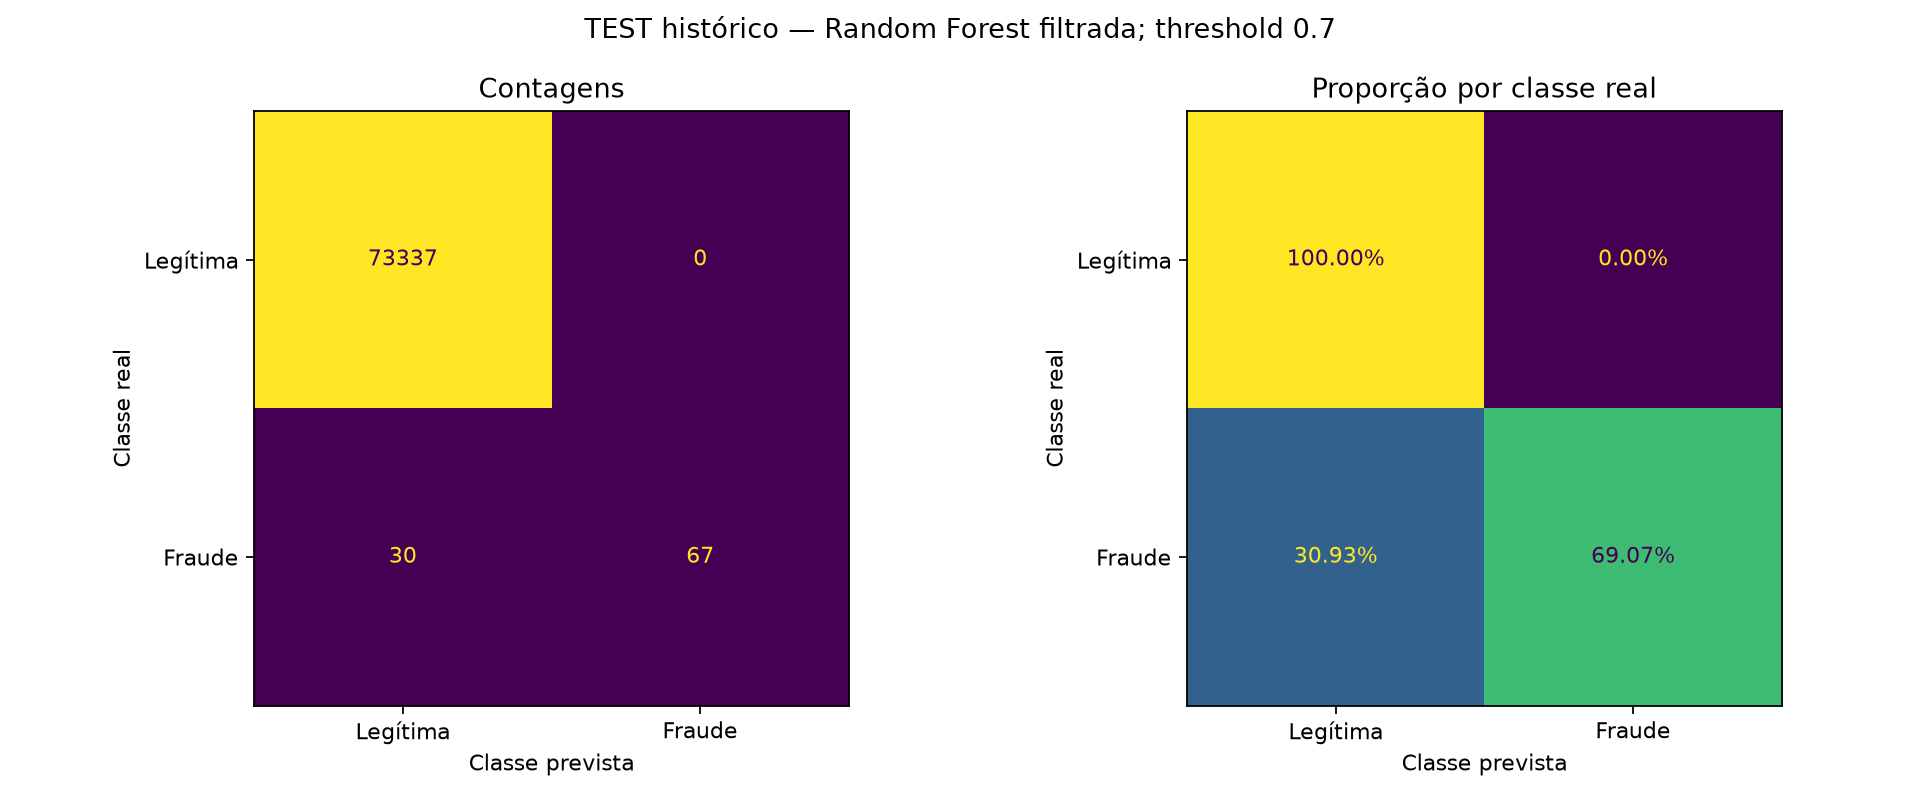

In [4]:
display(readable_table(pd.DataFrame([{key: result[key] for key in ["tn", "fp", "fn", "tp"]}])))
figure("final_test_confusion.png")

## 4. Todas as métricas percentuais, com fórmulas e denominadores
**FPR e parcela de alertas falsos não são a mesma métrica.**
FPR divide FP pelo total de legítimas; FDR divide FP pelo total de alertas.
Da mesma forma, FNR divide FN pelas fraudes, enquanto a parcela de liberadas
que era fraude divide FN por todas as transações liberadas.

Acurácia pode parecer excelente pela predominância de legítimas. Balanced
Accuracy dá o mesmo peso ao desempenho das duas classes.
Valores com unidade “%” já estão em escala **0–100** na tabela a seguir.

In [5]:
definitions = table("final_test_metric_definitions.csv")
percentage_metrics = definitions.loc[definitions.unit.eq("%")].rename(columns={
    "name": "Métrica", "value": "Valor (%)", "definition": "Significado e denominador",
    "preferred": "Direção desejável",
})
display(percentage_metrics[
    ["Métrica", "Valor (%)", "Significado e denominador", "Direção desejável"]
].style.format({"Valor (%)": "{:.4f}%"}))

,Métrica,Valor (%),Significado e denominador,Direção desejável
0,Precision,100.0000%,TP/(TP+FP): fração dos alertas que era fraude,Maior
1,Recall / sensibilidade,69.0722%,TP/(TP+FN): fração das fraudes detectada,Maior
2,F1,81.7073%,2PR/(P+R): média harmônica simétrica de Precision e Recall,Maior
3,F2,73.6264%,5PR/(4P+R): favorece Recall; objetivo usado no TRAIN,Maior
4,Especificidade,100.0000%,TN/(TN+FP): legítimas corretamente liberadas,Maior
5,Acurácia,99.9591%,(TP+TN)/n: acertos totais; pode enganar em classe rara,Maior
6,Balanced Accuracy,84.5361%,(Recall+Especificidade)/2,Maior
7,Valor preditivo negativo,99.9591%,TN/(TN+FN): legítimas entre não alertadas,Maior
8,Taxa de falsos positivos (FPR),0.0000%,FP/(FP+TN): legítimas alertadas,Menor
9,Taxa de falsos negativos (FNR),30.9278%,FN/(FN+TP): fraudes não detectadas,Menor


## 5. Scores probabilísticos e de concordância
- **AP:** resumo principal da curva PR calculado com probabilidades/scores.
- **Área trapezoidal PR:** outra forma de integrar a curva; não é idêntica à AP.
- **ROC-AUC:** qualidade da ordenação entre fraude e legítima; complementa AP.
- **Log Loss e Brier:** erros probabilísticos; menor é melhor.
- **MCC e Kappa:** concordância entre previsões e rótulos; maior é melhor.
  Valores próximos de 0 indicam ausência de concordância útil segundo cada definição.

Esses scores não são a taxa de acertos de uma classe. Log Loss não é o critério
de impureza de uma árvore. Brier baixo não comprova calibração por si só.

In [6]:
score_metrics = definitions.loc[~definitions.unit.eq("%")].rename(columns={
    "name": "Métrica", "value": "Valor", "unit": "Unidade",
    "definition": "Significado", "preferred": "Direção desejável",
})
display(score_metrics[
    ["Métrica", "Valor", "Unidade", "Significado", "Direção desejável"]
].style.format({"Valor": "{:.6f}"}))

,Métrica,Valor,Unidade,Significado,Direção desejável
14,Average Precision (AP),0.784309,score 0–1,Resumo de Precision ponderado pelos ganhos de Recall; usa scores,Maior
15,Área trapezoidal PR,0.784139,score 0–1,Integral trapezoidal da curva Precision–Recall; difere de AP,Maior
16,ROC-AUC,0.973428,score 0–1,Ordenação fraude vs. legítima; complemento à AP,Maior
17,Log Loss,0.007464,perda,Perda probabilística; penaliza erros confiantes,Menor
18,Brier score,0.000662,erro quadrático,Média de (probabilidade−rótulo)²,Menor
19,Coeficiente de Matthews (MCC),0.830927,score −1–1,Associação entre decisões e rótulos usando TN/FP/FN/TP,Maior
20,Kappa de Cohen,0.816876,score −1–1,Concordância corrigida pela concordância esperada ao acaso,Maior


## 6. Curvas Precision–Recall e ROC
A curva PR mostra Precision em função de Recall, ao variar o threshold sobre os
mesmos scores. A linha de prevalência é a referência ingênua. O ponto vermelho
marca **somente o limiar congelado 0,70**; a curva não foi usada para reajustá-lo.

Na ROC, os eixos são Recall (TPR) e FPR. O grande número de legítimas pode deixar
FPR muito pequeno mesmo quando existem falsos alertas; por isso PR/AP e contagens
devem ser lidos juntos.

,AP (score),pr_auc_trapezoid,ROC-AUC (score)
0,"0,7843","0,7841","0,9734"


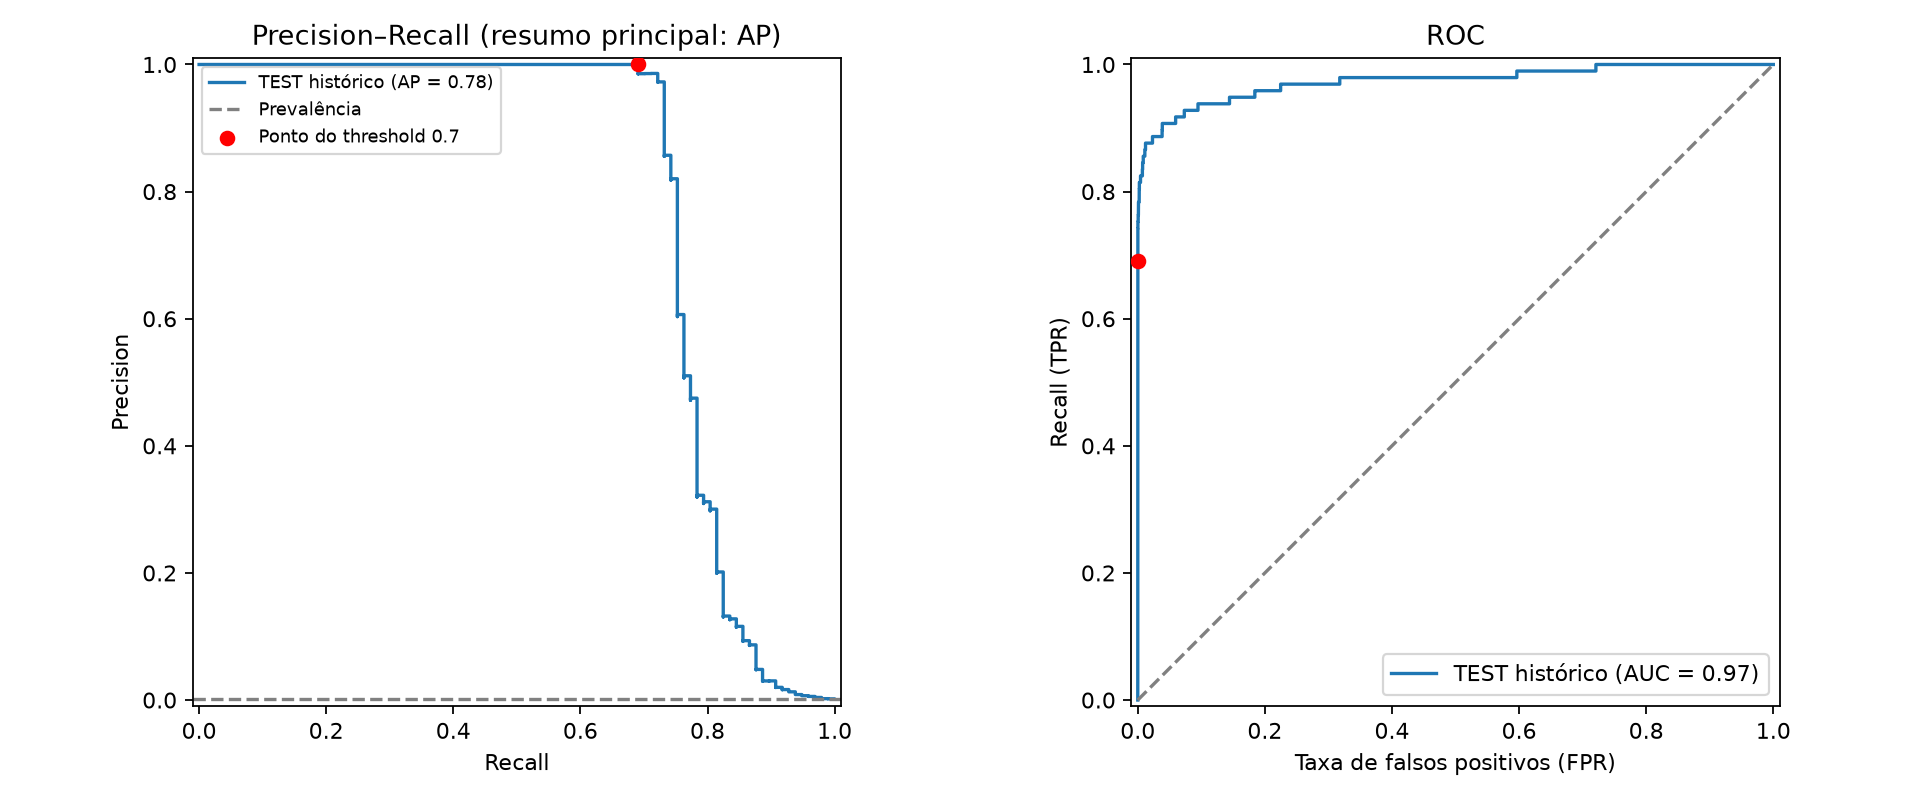

In [7]:
display(readable_table(pd.DataFrame([{key: result[key] for key in
    ["average_precision", "pr_auc_trapezoid", "roc_auc"]
}])))
figure("final_test_pr_roc.png")

## 7. Relatório por classe, média macro e média ponderada
Na linha de **Fraude (1)**, Recall e Precision têm a interpretação usada no resumo.
Na linha de **Legítima (0)**, a própria classe 0 é tratada como positiva para esse
cálculo: seu Recall equivale à especificidade, e sua Precision ao valor preditivo
negativo do problema de detecção de fraude.

**Suporte** é a quantidade de exemplos reais da classe. **Macro** dá peso igual
às classes. **Ponderada** usa o suporte, ficando dominada pelas legítimas nesta base;
uma média ponderada alta não significa que todas as fraudes foram detectadas.

In [8]:
classification = read_json(METRICS / "final_test_classification_report.json")
per_class = pd.DataFrame({
    key: value for key, value in classification.items() if isinstance(value, dict)
}).T.rename(columns={"f1-score": "f1", "support": "Suporte (transações reais)"})
per_class["Suporte (transações reais)"] = per_class["Suporte (transações reais)"].astype(int)
per_class = per_class.rename(index={
    "macro avg": "Média macro (pesos iguais)",
    "weighted avg": "Média ponderada (por suporte)",
})
display(readable_table(per_class))

,Precision (%),Recall (%),F1 (%),Suporte (transações reais)
Legítima (0),99.96%,100.00%,99.98%,73.337
Fraude (1),100.00%,69.07%,81.71%,97
Média macro (pesos iguais),99.98%,84.54%,90.84%,73.434
Média ponderada (por suporte),99.96%,99.96%,99.96%,73.434


## 8. Qualidade das probabilidades e distribuição dos scores
No gráfico de confiabilidade, cada ponto reúne uma faixa de scores: compara a
probabilidade prevista média com a frequência real de fraude. A diagonal é a
referência de calibração ideal. As faixas são um diagnóstico posterior; **nenhum
calibrador foi ajustado no TEST**.

SMOTE alterou a distribuição no treino, e os scores não foram calibrados.
Não se deve interpretar automaticamente score 0,70 como 70% de chance operacional
de fraude. A distribuição à direita é normalizada **dentro de cada classe**:
cada histograma soma 100%, permitindo comparar formatos apesar do desbalanceamento.

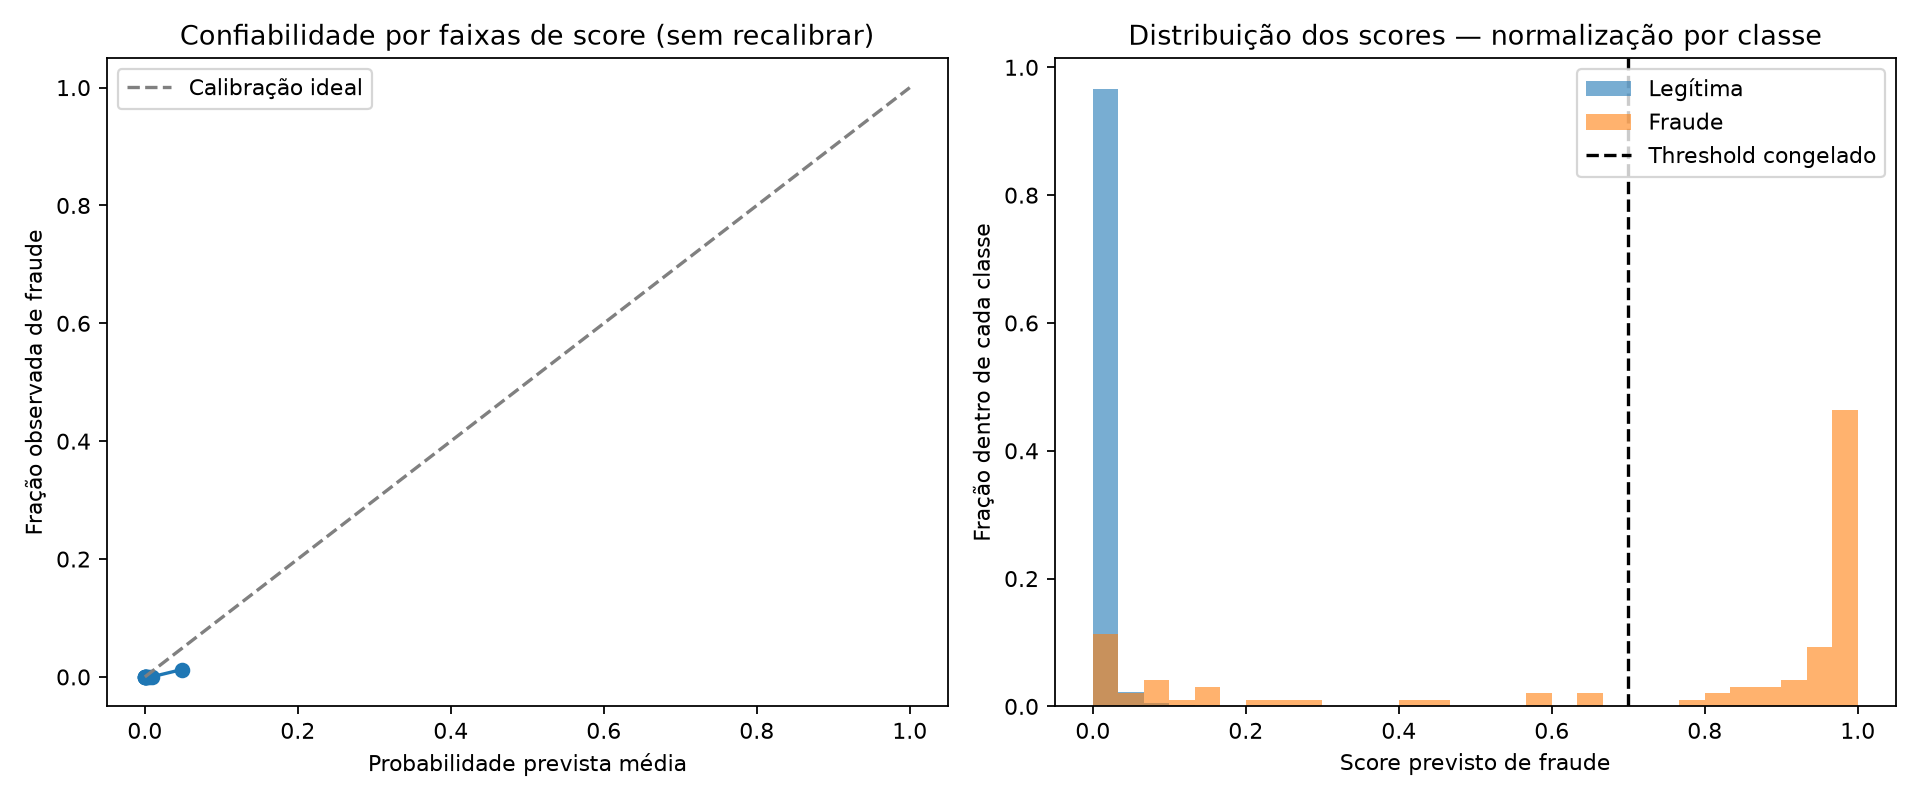

,Faixa de score,Transações,Fraudes,Probabilidade média prevista,Frequência real de fraude,Score mínimo,Score máximo
0,"(-0.001, 0.000251]",7356,0,0.0161%,0.0000%,0.0000,0.0003
1,"(0.000251, 0.000403]",7331,0,0.0325%,0.0000%,0.0003,0.0004
2,"(0.000403, 0.000612]",7343,1,0.0501%,0.0136%,0.0004,0.0006
3,"(0.000612, 0.000937]",7344,0,0.0763%,0.0000%,0.0006,0.0009
4,"(0.000937, 0.00145]",7343,1,0.1173%,0.0136%,0.0009,0.0014
5,"(0.00145, 0.00231]",7343,0,0.1848%,0.0000%,0.0014,0.0023
6,"(0.00231, 0.00375]",7344,1,0.2958%,0.0136%,0.0023,0.0038
7,"(0.00375, 0.00645]",7343,1,0.4944%,0.0136%,0.0038,0.0064
8,"(0.00645, 0.0135]",7343,2,0.9218%,0.0272%,0.0065,0.0135
9,"(0.0135, 1.0]",7344,91,4.8006%,1.2391%,0.0135,0.9997


In [9]:
figure("final_test_calibration_scores.png")
calibration = table("final_test_calibration.csv").rename(columns={
    "score_bin": "Faixa de score",
    "count": "Transações",
    "fraud_count": "Fraudes",
    "predicted_probability": "Probabilidade média prevista",
    "observed_fraud_rate": "Frequência real de fraude",
    "min_probability": "Score mínimo",
    "max_probability": "Score máximo",
})
display(calibration.style.format({
    "Probabilidade média prevista": "{:.4%}",
    "Frequência real de fraude": "{:.4%}",
    "Score mínimo": "{:.4f}",
    "Score máximo": "{:.4f}",
}))

## 9. Erros ao longo do período de TEST
As quatro janelas abaixo particionam cronologicamente o próprio TEST para descrever
onde os erros ocorreram. Isso não é CV e não foi usado para escolher o modelo.
Cada taxa deve ser interpretada junto com a quantidade de fraudes e legítimas:
poucos eventos tornam os percentuais instáveis.

In [10]:
display(readable_table(table("final_test_time_segments.csv")))

,time_interval,Quantidade,Fraudes confirmadas,TP: fraudes detectadas,FP: falsos alertas,FN: fraudes não detectadas,TN: legítimas liberadas,Recall da faixa (%),Precision da faixa (%),Falsos positivos entre legítimas (%),Fraude na faixa (%)
0,"(138199.442, 146873.5]",20.528,27,19,0,8,20.501,70.37%,100.00%,0.00%,0.1315%
1,"(146873.5, 155513.0]",20.079,38,27,0,11,20.041,71.05%,100.00%,0.00%,0.1893%
2,"(155513.0, 164152.5]",18.672,21,16,0,5,18.651,76.19%,100.00%,0.00%,0.1125%
3,"(164152.5, 172792.0]",14.155,11,5,0,6,14.144,45.45%,100.00%,0.00%,0.0777%


## 10. Fraudes e erros por faixa de feature
As fronteiras dos quantis foram aprendidas no **TRAIN**, depois aplicadas ao TEST.
Os extremos foram estendidos para cobrir valores futuros fora do alcance do treino.
Essas faixas não representam modalidades reais de fraude.

- **Fraude na faixa (%):** fraudes reais / transações da faixa.
- **Recall da faixa (%):** TP/(TP+FN).
- **Precision da faixa (%):** TP/(TP+FP).
- **Falsos positivos entre legítimas (%):** FP/(FP+TN).
- **Alertas que eram falsos (%):** FP/(FP+TP).

“Não definido” significa denominador zero, não desempenho nulo. Cada feature
particiona as mesmas transações: **não some linhas de features diferentes**.

In [11]:
# Altere somente esta variável para inspecionar outra feature, sem recalcular o modelo.
FEATURE_TO_INSPECT = "V10"
segments = table("final_test_feature_segments.csv")
display(readable_table(segments.loc[
    segments.feature.eq(FEATURE_TO_INSPECT),
    ["feature", "bin", "count", "fraud_count", "legitimate_count",
     "tp", "fp", "fn", "tn", "fraud_rate_pct", "recall_pct", "precision_pct",
     "false_positive_rate_pct", "missed_fraud_rate_pct", "false_alert_share_pct", "alert_rate_pct"]
]))
display(Markdown(
    "O CSV **reports/metrics/final_test_feature_segments.csv** contém todas as 30 "
    "features originais para diagnóstico, embora o modelo use apenas as 14 mantidas."
))

,Feature,Faixa de valores,Quantidade,Fraudes confirmadas,Transações legítimas,TP: fraudes detectadas,FP: falsos alertas,FN: fraudes não detectadas,TN: legítimas liberadas,Fraude na faixa (%),Recall da faixa (%),Precision da faixa (%),Falsos positivos entre legítimas (%),Fraudes não detectadas (%),Alertas que eram falsos (%),Taxa de alertas da faixa (%)
91,V10,"(-0.643, -0.414]",6.687,2,6.685,0,0,2,6.685,0.0299%,0.00%,Não definido,0.00%,100.0000%,Não definido,0.00%
92,V10,"(-0.414, -0.245]",6.065,2,6.063,0,0,2,6.063,0.0330%,0.00%,Não definido,0.00%,100.0000%,Não definido,0.00%
93,V10,"(0.0468, 0.262]",8.948,4,8.944,0,0,4,8.944,0.0447%,0.00%,Não definido,0.00%,100.0000%,Não definido,0.00%
94,V10,"(-inf, -1.019]",8.249,77,8.172,67,0,10,8.172,0.9334%,87.01%,100.00%,0.00%,12.9870%,0.00%,0.81%
95,V10,"(-1.019, -0.643]",8.878,3,8.875,0,0,3,8.875,0.0338%,0.00%,Não definido,0.00%,100.0000%,Não definido,0.00%
96,V10,"(1.06, inf]",9.003,5,8.998,0,0,5,8.998,0.0555%,0.00%,Não definido,0.00%,100.0000%,Não definido,0.00%
97,V10,"(0.262, 0.626]",6.403,1,6.402,0,0,1,6.402,0.0156%,0.00%,Não definido,0.00%,100.0000%,Não definido,0.00%
98,V10,"(0.626, 1.06]",7.385,1,7.384,0,0,1,7.384,0.0135%,0.00%,Não definido,0.00%,100.0000%,Não definido,0.00%
99,V10,"(-0.245, -0.0971]",6.108,1,6.107,0,0,1,6.107,0.0164%,0.00%,Não definido,0.00%,100.0000%,Não definido,0.00%
100,V10,"(-0.0971, 0.0468]",5.708,1,5.707,0,0,1,5.707,0.0175%,0.00%,Não definido,0.00%,100.0000%,Não definido,0.00%


O CSV **reports/metrics/final_test_feature_segments.csv** contém todas as 30 features originais para diagnóstico, embora o modelo use apenas as 14 mantidas.

## 11. Conclusão da avaliação congelada e limitações
Este resultado descreve um único modelo e um único threshold, definidos antes
desta execução. Não há tabela de candidatos no TEST nem busca de um limiar novo.
O período, porém, já havia sido visto anteriormente: **não se trata de confirmação
independente de toda a sequência de decisões do projeto**.

Há apenas dois dias e poucas fraudes no período final. Não foram estimados
intervalos de confiança temporais robustos. Os componentes PCA originais e grupos
de cartão/cliente não puderam ser auditados. Os scores não foram calibrados e
custos de FP/FN não foram informados. Zero FP nesta amostra não garante zero FP
em novas transações; alta acurácia não elimina as fraudes perdidas.

Próxima validação independente: outro período externo, preservando integralmente
pipeline, features e threshold. Se houver mudança após ler este notebook, essa
mudança precisará de novos dados para avaliação independente.

In [12]:
display(Markdown(
    f"**Resultado observado:** Recall **{result['recall']:.2%}**, "
    f"Precision **{result['precision']:.2%}**, F1 **{result['f1']:.2%}**, "
    f"F2 **{result['f2']:.2%}** e AP **{result['average_precision']:.4f}**. "
    f"Foram **{result['tp']} fraudes detectadas**, **{result['fn']} não detectadas** "
    f"e **{result['fp']} falsos alertas**, com threshold **{result['threshold']}**."
))
display(manifest["limitations"])

**Resultado observado:** Recall **69.07%**, Precision **100.00%**, F1 **81.71%**, F2 **73.63%** e AP **0.7843**. Foram **67 fraudes detectadas**, **30 não detectadas** e **0 falsos alertas**, com threshold **0.7**.

['TEST já avaliado na primeira rodada; resultado retrospectivo, não confirmação independente.',
 'Nenhum ajuste foi realizado em resposta a este resultado.',
 'Poucas fraudes e apenas dois dias; sem intervalos de confiança temporais robustos.',
 'SMOTE altera a distribuição de treino; scores não são probabilidades calibradas demonstradas.',
 'Subgrupos e faixas são diagnósticos posteriores, não motivos para retuning neste TEST.']